# Visualization of flows

In [1]:
#packages
import os
import pandas as pd 
import numpy as np
import seaborn as sns
from joypy import joyplot
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
import matplotlib.ticker as ticker
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ListedColormap

#### Data preparation

In [4]:
years = [1997, 2002, 2007, 2012, 2017, 2022]

In [6]:
#read the data
F0a_1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F0a_1")
F0b_1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F0b_1")
F1_3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F1_3")
F2_1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F2_1")
F1_0 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "total_exp")
F3_0 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F3_0")
F3_4 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F3_4")
F5_3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "reuse_flows") #precalculated data, based on F9_0 and C&D reuse
F5_7 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_7")
F5_6 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_6")
F5_8 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_8")
F5_9 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_9")
F7_8 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F7_8")
F7_9 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F7_9")
deltaS8 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "deltaS8")
F9_0 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F9_0")#with m != "green waste","food" and "final products"
#deltaS3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "deltaS3")
#deltaS3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "deltaS3_Holt")

In [8]:
F0a_1 = F0a_1[F0a_1['Year'].isin(years)]
F0b_1 = F0b_1[F0b_1['Year'].isin(years)]
F1_3 = F1_3[F1_3['Year'].isin(years)]
F2_1 = F2_1[F2_1['Year'].isin(years)]
F1_0 = F1_0[F1_0['Year'].isin(years)]
F3_4 = F3_4[F3_4['Year'].isin(years)]
F5_3 = F5_3[F5_3['Year'].isin(years)]
F5_7 = F5_7[F5_7['Year'].isin(years)]
F5_6 = F5_6[F5_6['Year'].isin(years)]
F5_8 = F5_8[F5_8['Year'].isin(years)]
F5_9 = F5_9[F5_9['Year'].isin(years)]
F7_8 = F7_8[F7_8['Year'].isin(years)]
F7_9 = F7_9[F7_9['Year'].isin(years)]
F9_0 = F9_0[F9_0['Year'].isin(years)]
# deltaS3 = deltaS3[deltaS3['Year'].isin(years)]
# deltaS3 = deltaS3[deltaS3['Material'] != "sewage sludge (tonnage data being researched)"]
deltaS8 = deltaS8[deltaS8['Year'].isin(years)]
deltaS8 = (deltaS8.groupby(['Material', 'Year'], as_index=False)['kilotons']
           .sum()
          )

In [10]:
F3_4 = F3_4[F3_4['Material'] != "sewage sludge (tonnage data being researched)"]

In [12]:
exclude = ['green waste', 'food', 'final products', 'sewage sludge (tonnage data being researched)']
F9_0 = F9_0[~F9_0["Material"].isin(exclude)]
F9_0 = (F9_0.rename(columns={'Tons':'kilotons'})
       .groupby(['Material', 'Year'], as_index=False)['kilotons']
       .sum())

#### Figures

In [15]:
# Define a custom color palette for products using hex color codes and all categories!
product_colors = {
    "food": "#9ACD32",       
    "construction material and minerals": "#F5DEB3",
    "fossil fuels": "#778899",
    "chemicals": "#D8BFD8",
    "plastic": "#BC8F8F",
    "wood": "#CD853F",
    "paper": "#FAF0E6",
    "final products": "#ADD8E6",
    "metals": "#A9A9A9",
    "electronics": "#D3D3D3",
    "motorized vehicles": "#4682B4",
    "waste": "#DAA520",
    "mixed freight": "#5F9EA0",
    "glass": "#F0FFFF",
    "green waste": "#006400",
    "residual waste and ashes": "#A8968C",
    "sewage sludge": "#6C6C6C"
}

##### DMI - Imports and Domestic Extraction (incl. Packaging materials)
F0a_1, F0b_a, F2_1

In [18]:
display(F0a_1, F0b_1, F2_1)

,Year,Material,Source,Target,kilotons
0,1997,chemicals,Imports,DMI,69.728243
1,1997,construction material and minerals,Imports,DMI,587.528504
2,1997,electronics,Imports,DMI,32.311510
3,1997,final products,Imports,DMI,198.335201
4,1997,food,Imports,DMI,692.187348
...,...,...,...,...,...
73,2022,motorized vehicles,Imports,DMI,103.878164
74,2022,paper,Imports,DMI,75.185845
75,2022,plastic,Imports,DMI,91.008398
76,2022,waste,Imports,DMI,0.006249


,Year,Material,kilotons,Source,Target
0,1997,chemicals,0.000000,Indirect Imports of Packaging,DMI
1,1997,construction material and minerals,0.000000,Indirect Imports of Packaging,DMI
2,1997,electronics,0.000000,Indirect Imports of Packaging,DMI
3,1997,final products,0.000000,Indirect Imports of Packaging,DMI
4,1997,food,0.000000,Indirect Imports of Packaging,DMI
...,...,...,...,...,...
99,2022,paper,50.512040,Indirect Imports of Packaging,DMI
100,2022,plastic,5.652936,Indirect Imports of Packaging,DMI
101,2022,sewage sludge,0.000000,Indirect Imports of Packaging,DMI
102,2022,waste,0.000000,Indirect Imports of Packaging,DMI


,Year,Material,kilotons,Source,Target
0,1997,food,367.762911,DE,DMI
1,2002,food,172.993250,DE,DMI
2,2007,food,219.752215,DE,DMI
3,2012,food,538.951586,DE,DMI
4,2017,food,586.492707,DE,DMI
5,2022,food,489.847440,DE,DMI
32,1997,construction material and minerals,4443.415673,DE,DMI
37,2002,construction material and minerals,5230.629093,DE,DMI
42,2007,construction material and minerals,7969.413424,DE,DMI
47,2012,construction material and minerals,4322.190792,DE,DMI


In [20]:
pivot = F0b_1.pivot(
    index='Year',
    columns='Material',
    values='kilotons'
).fillna(0)

In [22]:
display(pivot)

Material,chemicals,construction material and minerals,electronics,final products,food,glass,green waste,metals,motorized vehicles,paper,plastic,sewage sludge,waste,wood
Year,,,,,,,,,,,,,,
1997,0.0,0.0,0.0,0.0,0.0,11.068369,0.0,9.738572,0.0,44.346644,2.683674,0.0,0.0,8.789915
2002,0.0,0.0,0.0,0.0,0.0,11.445017,0.0,9.982582,0.0,51.324056,9.131206,0.0,0.0,0.098509
2007,0.0,0.0,0.0,0.0,0.0,20.812653,0.0,13.270354,0.0,62.701248,13.386957,0.0,0.0,0.100498
2012,0.0,0.0,0.0,0.0,0.0,23.063720,0.0,14.207997,0.0,52.001477,7.685841,0.0,0.0,1.417185
2017,0.0,0.0,0.0,0.0,0.0,14.846144,0.0,22.774282,0.0,55.898281,7.679689,0.0,0.0,5.161442
2022,0.0,0.0,0.0,0.0,0.0,9.072162,0.0,13.819333,0.0,50.512040,5.652936,0.0,0.0,5.162153


In [24]:
F0b_1= F0b_1[F0b_1['kilotons'] > 0]

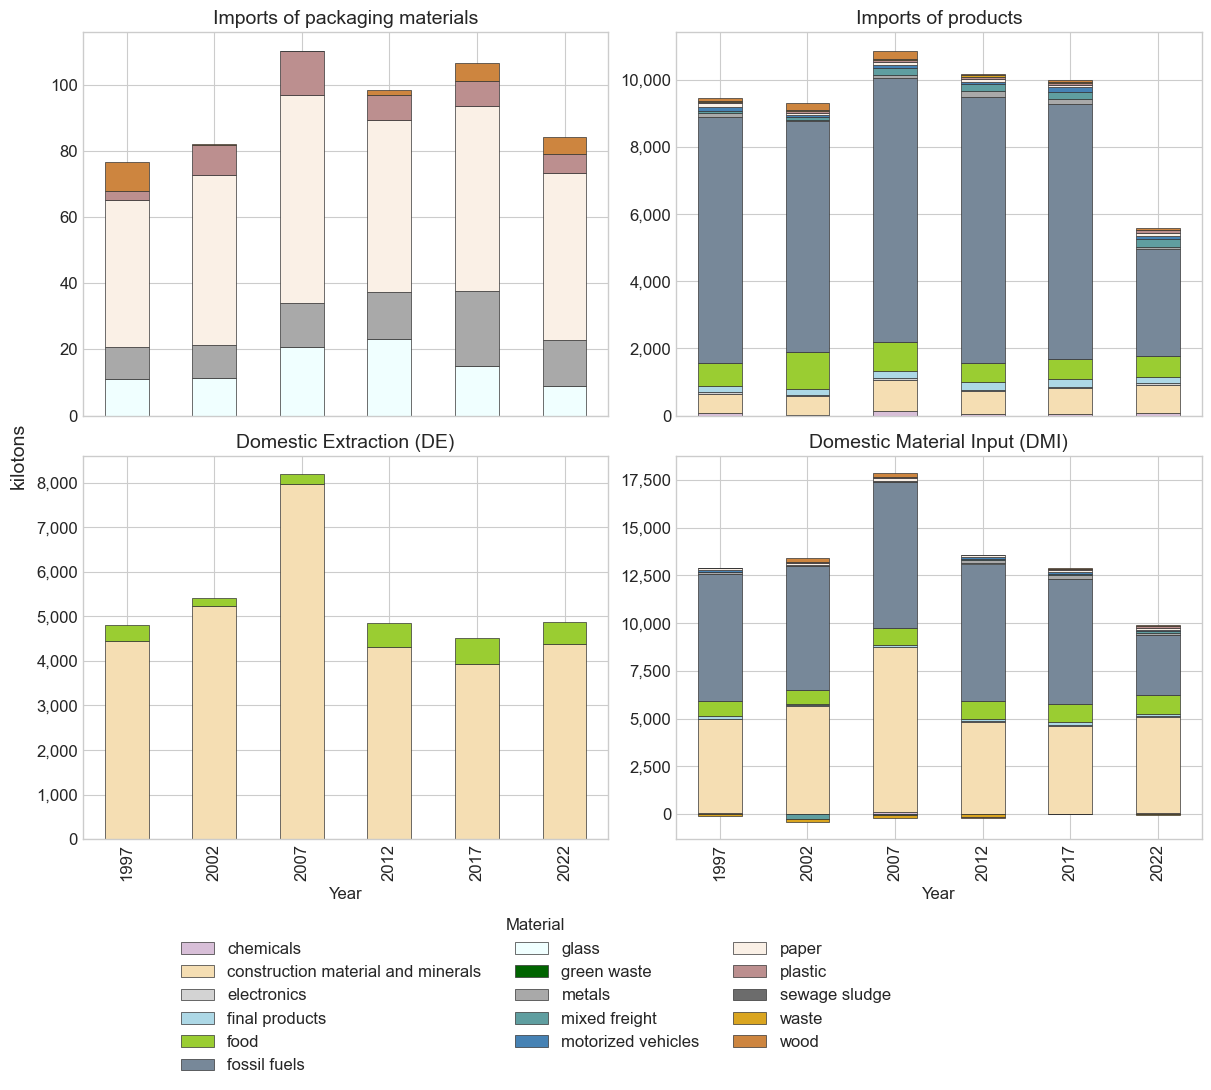

In [26]:
plt.style.use("seaborn-v0_8-whitegrid")
datasets = [F0b_1, F0a_1, F2_1, F1_3]
titles = ["Imports of packaging materials", "Imports of products", "Domestic Extraction (DE)", "Domestic Material Input (DMI)"]

plt.rcParams.update({
    "axes.labelsize": 12,   
    "xtick.labelsize": 12,  
    "ytick.labelsize": 12   
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    sharex=True,
    layout="constrained"
)

#axes[1,1].sharey(axes[1,0])
axes[1,1].tick_params(labelleft=True)
axes[1,1].spines["left"].set_visible(True)

for ax, data, title in zip(axes.flat, datasets, titles):

    pivot_df = data.pivot(
        index="Year",
        columns="Material",
        values="kilotons"
    )

    pivot_df.plot.bar(
        stacked=True,
        color=[product_colors[col] for col in pivot_df.columns],
        edgecolor="#333333",
        linewidth=0.5,
        ax=ax,
        legend=False   
    )

    ax.set_title(title, fontsize = 14) #title, fontsize=14, fontweight="bold", fontfamily="Arial"
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )

# shared y-axis
fig.supylabel("kilotons", fontsize=14)

# shared legend
handles, labels = axes[1,1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center right",
    bbox_to_anchor=(0.75, -0.1),
    ncol = 3,
    frameon=False,
    title="Material",
    fontsize = 12,
    title_fontsize = 12
)
# plt.rcParams.update({
#     "font.family": "Arial",      # oder "Times New Roman"
#     "axes.titlesize": 14,
#     "axes.titleweight": "bold"
# })
fig.savefig('inflows.jpg', dpi = 600,bbox_inches='tight')
plt.show()

In [27]:
# subset withoutout high-volume materials
subset1 = (F0a_1
        .query("Material not in ['food', 'fossil fuels', 'construction material and minerals', 'green waste', 'sewage sludge']"))
# subset with high-volume materials
subset2 = subset = (F0a_1
        .query("Material in ['food', 'fossil fuels', 'construction material and minerals']"))

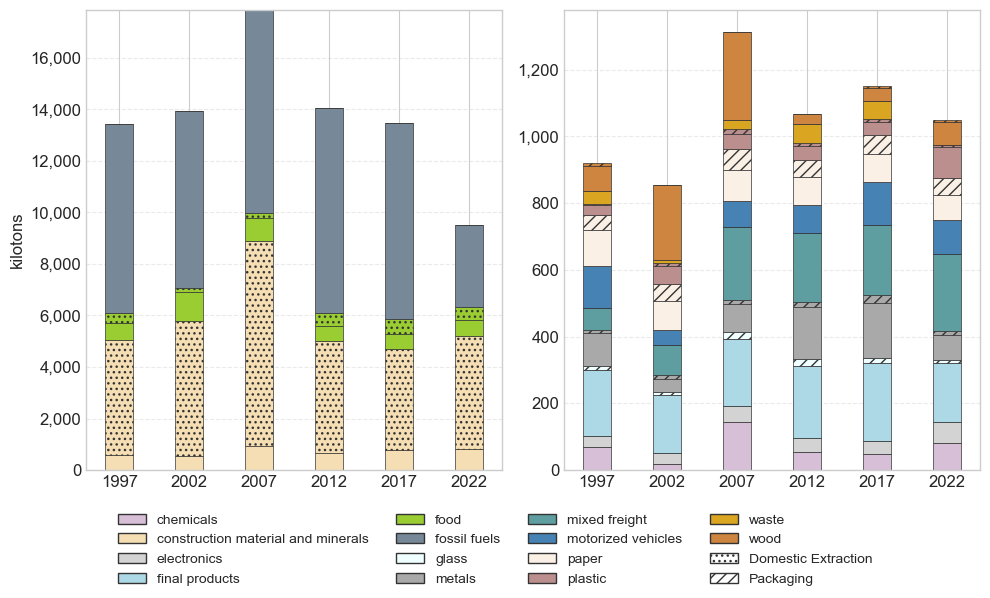

In [28]:
#new version with same legend and different pattern for DE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

# first plot
pivot_products = subset2.pivot(index="Year", columns="Material", values="kilotons")
pivot_packaging = F2_1.pivot(index="Year", columns="Material", values="kilotons")

materials = sorted(set(pivot_products.columns).union(pivot_packaging.columns))
pivot_products = pivot_products.reindex(columns=materials).fillna(0)
pivot_packaging = pivot_packaging.reindex(columns=materials).fillna(0)

years = pivot_products.index
bottom = np.zeros(len(years))

for mat in materials:
    vals_prod = pivot_products[mat].values
    ax1.bar(years, vals_prod, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2)
    bottom += vals_prod

    vals_pack = pivot_packaging[mat].values
    ax1.bar(years, vals_pack, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2,
            hatch="...")
    bottom += vals_pack
    ax1.set_xticks(years)
    ax1.set_xticklabels(years)
    ax1.set_ylabel("kilotons")

#ax1.set_title("Imports and Domestic Extraction of high-volume materials", fontsize=12, fontweight="bold")


# second plot
pivot_products = subset1.pivot(index="Year", columns="Material", values="kilotons")
pivot_packaging = F0b_1.pivot(index="Year", columns="Material", values="kilotons")

materials2 = sorted(set(pivot_products.columns).union(pivot_packaging.columns))
pivot_products = pivot_products.reindex(columns=materials2).fillna(0)
pivot_packaging = pivot_packaging.reindex(columns=materials2).fillna(0)

years = pivot_products.index
bottom = np.zeros(len(years))

for mat in materials2:
    vals_prod = pivot_products[mat].values
    ax2.bar(years, vals_prod, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2)
    bottom += vals_prod

    vals_pack = pivot_packaging[mat].values
    ax2.bar(years, vals_pack, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2,
            hatch="///")
    bottom += vals_pack
    ax2.set_xticks(years)
    ax2.set_xticklabels(years)

#ax2.set_title("Imports of low-volume materials", fontsize=12, fontweight="bold")


# common design
for ax in (ax1, ax2):
    ax.set_facecolor("white")
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )


# shared legend
all_materials = sorted(set(materials).union(materials2))

material_handles = [
    Patch(facecolor=product_colors[m], edgecolor="#333333", label=m)
    for m in all_materials
]

hatch_handles = [
    Patch(facecolor="white", edgecolor="#333333", hatch="...", label="Domestic Extraction"),
    Patch(facecolor="white", edgecolor="#333333", hatch="///", label="Packaging")
]

handles = material_handles + hatch_handles
labels = [h.get_label() for h in handles]

fig.legend(handles, labels,
           loc="lower center",
           ncol=4,
           frameon=False)

# Platz für Legende unten schaffen
plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.savefig('input.jpg', dpi = 600,bbox_inches='tight')
plt.show()


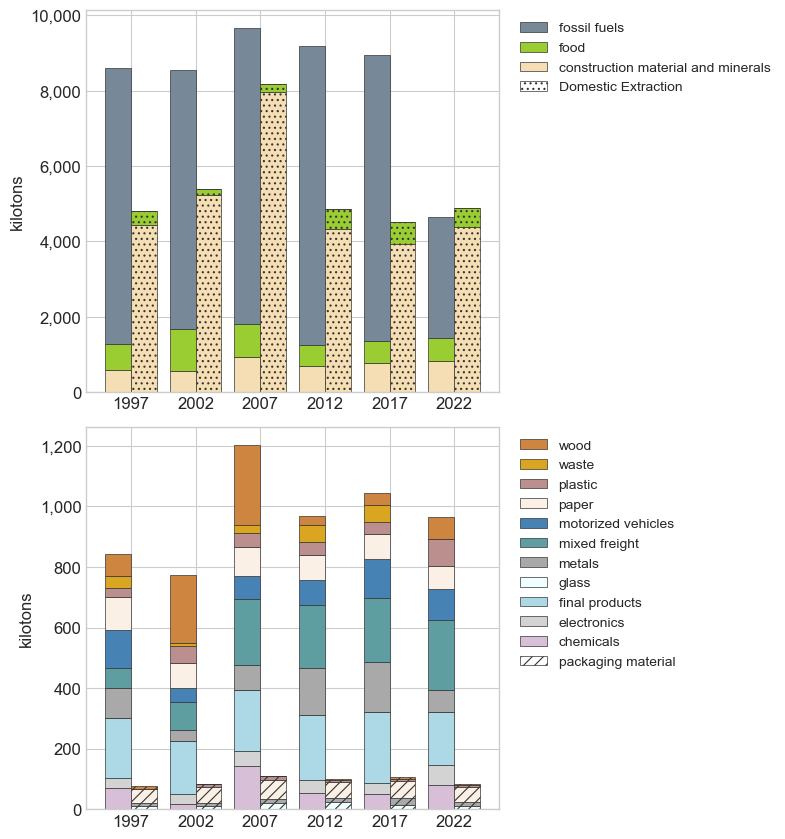

In [29]:
# revised figure: two distinct legends and bars with DE / packaging next to other bars and on top of each other
#new version with same legend and different pattern for DE
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10), sharey=False)

pivot_products = subset2.pivot(
    index="Year", columns="Material", values="kilotons"
)
pivot_packaging = F2_1.pivot(
    index="Year", columns="Material", values="kilotons"
)

materials = sorted(
    set(pivot_products.columns).union(pivot_packaging.columns)
)

pivot_products = pivot_products.reindex(columns=materials).fillna(0)
pivot_packaging = pivot_packaging.reindex(columns=materials).fillna(0)

years = pivot_products.index

# Bar positioning
bar_width = 0.5
group_gap = 0.25
x = np.arange(len(years)) * (2 * bar_width + group_gap)

# Separate bottom arrays for each stacked bar
bottom_prod = np.zeros(len(years))
bottom_pack = np.zeros(len(years))

# Plot product bars (left)
for mat in materials:
    vals = pivot_products[mat].values

    ax1.bar(
        x - bar_width/2,
        vals,
        bottom=bottom_prod,
        color=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        width=bar_width
    )

    bottom_prod += vals

# Plot packaging bars (right)
for mat in materials:
    vals = pivot_packaging[mat].values

    ax1.bar(
        x + bar_width/2,
        vals,
        bottom=bottom_pack,
        color=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        width=bar_width,
        hatch="..."
    )

    bottom_pack += vals

# Axis formatting
ax1.set_xticks(x)
ax1.set_xticklabels(years)
ax1.set_ylabel("kilotons")
ax1.yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)


#from matplotlib.patches import Patch

legend_handles = [
    Patch(
        facecolor=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        label=mat
    )
    for mat in reversed(materials)
]

# Add one extra legend entry for the hatch pattern
legend_handles.append(
    Patch(
        facecolor="white",
        edgecolor="#333333",
        linewidth=0.5,
        hatch="...",
        label="Domestic Extraction"
    )
)

ax1.legend(
    handles=legend_handles,
    title="",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

#ax1.set_title("Imports and Domestic Extraction of high-volume materials", fontsize=12, fontweight="bold")

# second plot
pivot_products = subset1.pivot(index="Year", columns="Material", values="kilotons")
pivot_packaging = F0b_1.pivot(index="Year", columns="Material", values="kilotons")

materials2 = sorted(set(pivot_products.columns).union(pivot_packaging.columns))

pivot_products = pivot_products.reindex(columns=materials2).fillna(0)
pivot_packaging = pivot_packaging.reindex(columns=materials2).fillna(0)

years = pivot_products.index
bottom = np.zeros(len(years))

bottom_prod = np.zeros(len(years))
bottom_pack = np.zeros(len(years))

# Bar positioning
bar_width = 0.5
group_gap = 0.25
x = np.arange(len(years)) * (2 * bar_width + group_gap)

# Plot product bars (left)
for mat in materials2:
    vals = pivot_products[mat].values

    ax2.bar(
        x - bar_width/2,
        vals,
        bottom=bottom_prod,
        color=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        width=bar_width
    )

    bottom_prod += vals

# Plot packaging bars (right)
for mat in materials2:
    vals = pivot_packaging[mat].values

    ax2.bar(
        x + bar_width/2,
        vals,
        bottom=bottom_pack,
        color=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        width=bar_width,
        hatch="///"
    )

    bottom_pack += vals

# Axis formatting
ax2.set_xticks(x)
ax2.set_xticklabels(years)
ax2.set_ylabel("kilotons")
ax2.yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

legend_handles = [
    Patch(
        facecolor=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        label=mat
    )
    for mat in reversed(materials2)
]

# extra legend entry for the hatch pattern
legend_handles.append(
    Patch(
        facecolor="white",
        edgecolor="#333333",
        linewidth=0.5,
        hatch="///",
        label="packaging material"
    )
)

ax2.legend(
    handles=legend_handles,
    title="",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

# placing the legend legend
plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.rcParams["hatch.color"] = "#333333"
plt.rcParams["hatch.linewidth"] = 0.8
plt.savefig('input_revised.jpg', dpi = 600,bbox_inches='tight')
plt.show()


##### EoL material shares

In [35]:
comp_reuse = (pd.concat([F5_3, F5_6])
             .groupby(['Material','Year'],as_index=False)['kilotons']
              .sum()
             )

In [37]:
EoL_strat = {
    "Reuse and Composting": comp_reuse,
    "Recycling off island":  F9_0,
    "WtE": F5_7,
    "Landfills": deltaS8
}

In [39]:
dfs = EoL_strat,
colors = product_colors,
value_col="kilotons",
year_col="Year",
material_col="Material",
figsize=(12, 6),
bar_width=0.25,
group_spacing=0.6,
group_order=None

In [41]:
datasets = [comp_reuse,F9_0,F5_7,deltaS8]
titles = ['reuse, recycling and composting', 'exports for recycling', 'WtE', 'landfills']

pivot_tables = [
    df.pivot(index="Year", columns="Material", values="kilotons").fillna(0)
    for df in datasets
]

In [43]:
years = pivot_tables[0].index
n_years = len(years)
n_groups = len(pivot_tables)

x = np.arange(n_years)

bar_width = 0.2
offsets = np.linspace(
    -bar_width*(n_groups-1)/2,
     bar_width*(n_groups-1)/2,
     n_groups
)

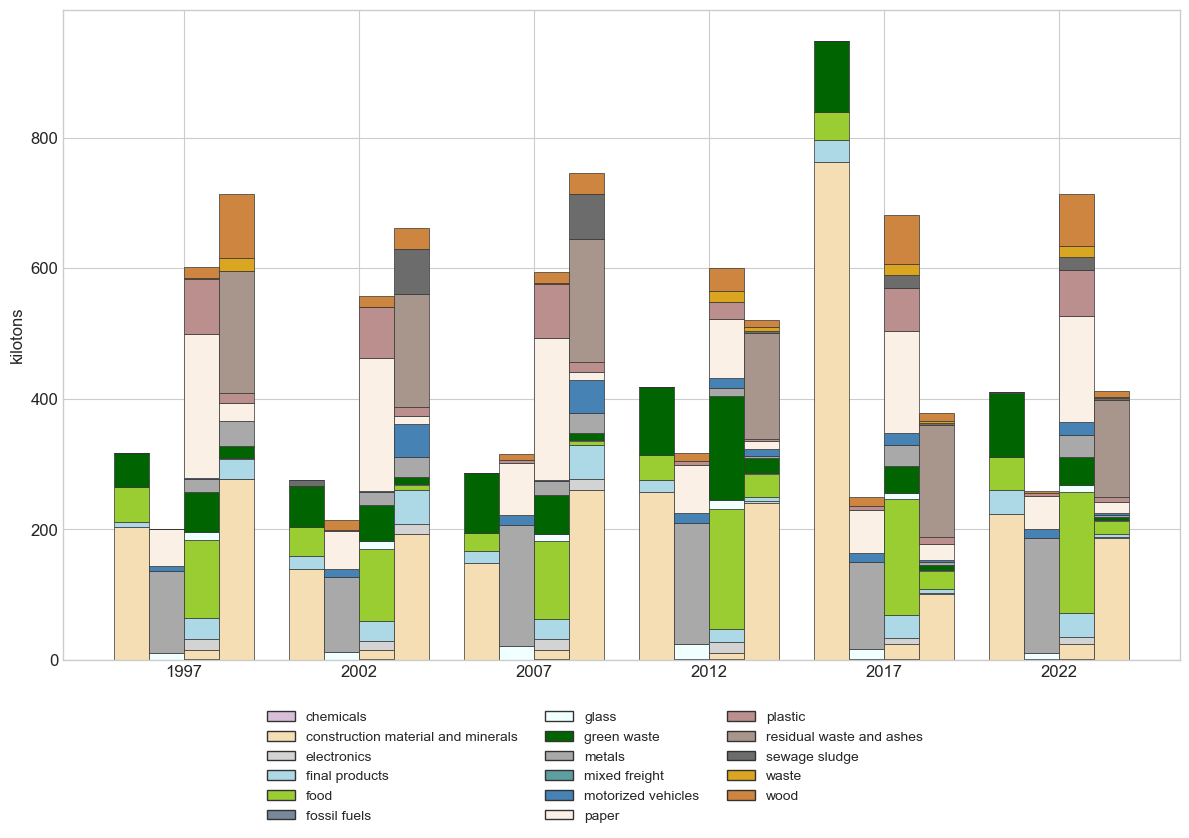

In [45]:
plt.rcParams.update({
    "axes.labelsize": 12,   
    "xtick.labelsize": 12,  
    "ytick.labelsize": 12   
})

fig, ax = plt.subplots(figsize=(12, 7), layout="tight")

for i, (pivot_df, offset, label) in enumerate(zip(pivot_tables, offsets, titles)):

    bottom = np.zeros(n_years)

    for material in pivot_df.columns:

        values = pivot_df[material].values

        ax.bar(
            x + offset,
            values,
            bar_width,
            bottom=bottom,
            color=product_colors.get(material, "#999999"),
            edgecolor="#333333",
            linewidth=0.5,
            label=material if i == 0 else None 
        )

        bottom += values

max_height = 0

for pivot_df in pivot_tables:
    stack_sum = pivot_df.sum(axis=1).max()
    max_height = max(max_height, stack_sum)

ax.set_ylim(0, max_height * 1.05) 

ax.set_xticks(x)
ax.set_xticklabels(years)
ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )

ax.set_ylabel("kilotons")

legend_handles = [
    Patch(facecolor=color, edgecolor="#333333", label=material)
    for material, color in sorted(product_colors.items())
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False#,
    #title="Material"
)

#fig.savefig('EoL.jpg', dpi = 600,bbox_inches='tight')



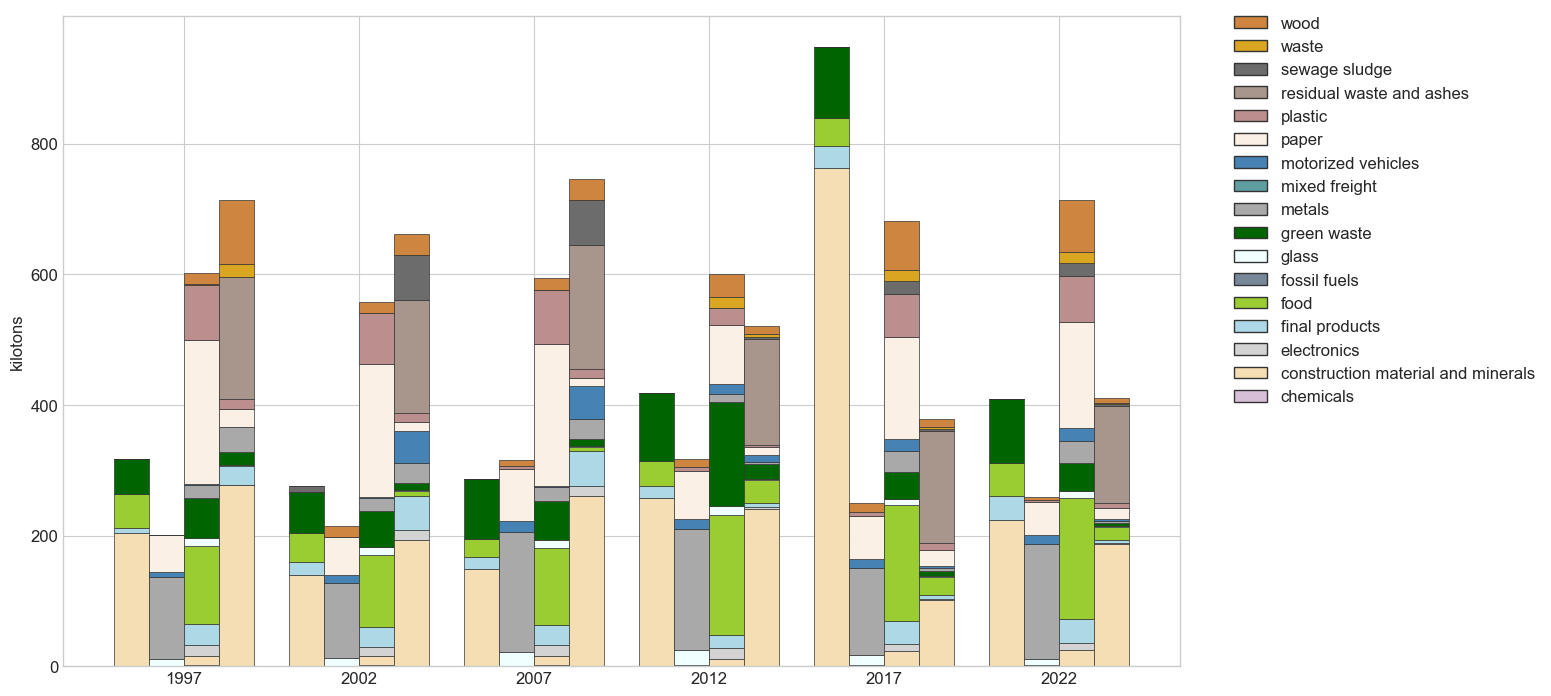

In [47]:
# revised version of this figure, to align with the design of the other figures
plt.rcParams.update({
    "axes.labelsize": 12,   
    "xtick.labelsize": 12,  
    "ytick.labelsize": 12   
})

fig, ax = plt.subplots(figsize=(12, 7), layout="tight")

for i, (pivot_df, offset, label) in enumerate(zip(pivot_tables, offsets, titles)):

    bottom = np.zeros(n_years)

    for material in pivot_df.columns:

        values = pivot_df[material].values

        ax.bar(
            x + offset,
            values,
            bar_width,
            bottom=bottom,
            color=product_colors.get(material, "#999999"),
            edgecolor="#333333",
            linewidth=0.5,
            label=material if i == 0 else None 
        )

        bottom += values

max_height = 0

for pivot_df in pivot_tables:
    stack_sum = pivot_df.sum(axis=1).max()
    max_height = max(max_height, stack_sum)

ax.set_ylim(0, max_height * 1.05) 

ax.set_xticks(x)
ax.set_xticklabels(years)
ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )

ax.set_ylabel("kilotons")

legend_handles = [
    Patch(facecolor=color, edgecolor="#333333", label=material)
    for material, color in sorted(product_colors.items())
]


fig.legend(
    handles=legend_handles[::-1],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    ncol=1,
    frameon=False,
    fontsize=12
    #title="Material"
)

fig.savefig('EoL.jpg', dpi = 600,bbox_inches='tight')

__Cumulative landfill data__

In [50]:
lf = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "total_waste_DOH_data")

In [52]:
lf.head()

,year,C&D Recycling,C&D Landfill,general recycling (MSW),WtE (MSW),WtE (ash & residue),landfill (MSW),Trash Shipping (MSW),total tonnage,CY WtE (Otsu + C&C Honolulu),WtE (MSW) - WtE (Otsu)
0,1997,NaN,214388.0,NaN,NaN,186551.176305,312923.00,NaN,NaN,602357.5,NaN
1,1998,NaN,196089.5,NaN,NaN,189174.505041,268925.50,NaN,NaN,610828.0,NaN
2,1999,NaN,197717.0,NaN,NaN,186482.732217,270820.25,NaN,NaN,602136.5,NaN
3,2000,NaN,187695.0,NaN,NaN,179852.172442,318631.00,NaN,NaN,580727.0,NaN
4,2001,NaN,172076.0,NaN,NaN,163857.315482,337449.00,NaN,NaN,529081.0,NaN


In [54]:
lf = lf.drop(columns={'C&D Recycling', 'general recycling (MSW)','CY WtE (Otsu + C&C Honolulu)', 'WtE (MSW)', 'Trash Shipping (MSW)', 'total tonnage', 'WtE (MSW) - WtE (Otsu)'})

In [56]:
lf['C&D Landfill'] = lf['C&D Landfill'].values / 1000
lf['WtE (ash & residue)'] = lf['WtE (ash & residue)'].values / 1000
lf['landfill (MSW)'] = lf['landfill (MSW)'].values / 1000

In [58]:
b1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", sheet_name = "factor b1") #2006, landfill
b2 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", sheet_name = "factor a2") #2017, WtE+landfill
b3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", sheet_name = "factor b3") #1998, landfill

In [59]:
#b1, b2, b3

In [60]:
factors_b1 = b1.copy().dropna().rename(columns={'mean tons': 'Tons'})
factors_b2 = b2.copy().dropna().rename(columns={'est tons': 'Tons'})
factors_b3 = b3.copy().dropna()
factors_b1["share"] = factors_b1['Tons']/factors_b1['Tons'].sum()
factors_b2["share"] = factors_b2['Tons']/factors_b2['Tons'].sum()
factors_b3["share"] = factors_b3['Tons']/factors_b3['Tons'].sum()

In [64]:
factors_b1 = (
    factors_b1
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b2 = (
    factors_b2
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b3 = (
    factors_b3
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b1['Year'] = 2006
factors_b2['Year'] = 2017
factors_b3['Year'] = 1998

In [66]:
b = pd.concat( 
    [factors_b1, factors_b2, factors_b3],
    ignore_index=True
)
b["Year"] = pd.to_numeric(b["Year"], errors="coerce").astype("Int64")
display(b)

,Material,share,Year
0,chemicals,0.000000,2006
1,construction material and minerals,0.036706,2006
2,electronics,0.050172,2006
3,final products,0.170494,2006
4,food,0.022043,2006
5,glass,0.005167,2006
6,green waste,0.034101,2006
7,metals,0.101454,2006
8,motorized vehicles,0.162178,2006
9,paper,0.042770,2006


In [68]:
wc = b.copy()

In [70]:
def get_wc_for_year(target_year, wc):
    wc = wc.copy()
    wc['dist'] = (wc['Year'] - target_year).abs()
    min_dist = wc['dist'].min()

    closest = wc[wc['dist'] == min_dist]

    # mean, if two years are equally close
    return (
        closest
        .groupby('Material', as_index=False)['share']
        .mean()
        .assign(year=target_year)
    )

In [72]:
rows = []

for _, r in lf.iterrows():
    year = r['year']
    total = r['landfill (MSW)']

    wc_y = get_wc_for_year(year, wc)

    wc_y['kilotons'] = wc_y['share'] * total
    rows.append(wc_y[['year', 'Material', 'kilotons']])

msw_lf_long = pd.concat(rows, ignore_index=True)

In [74]:
msw_lf_long

,year,Material,kilotons
0,1997.0,construction material and minerals,62.721078
1,1997.0,final products,30.105138
2,1997.0,glass,1.567211
3,1997.0,green waste,18.816323
4,1997.0,metals,38.523998
...,...,...,...
348,2023.0,paper,33.978313
349,2023.0,plastic,14.697590
350,2023.0,sewage sludge,4.298733
351,2023.0,waste,3.567042


In [76]:
lf

,year,C&D Landfill,WtE (ash & residue),landfill (MSW)
0,1997,214.38800,186.551176,312.923000
1,1998,196.08950,189.174505,268.925500
2,1999,197.71700,186.482732,270.820250
3,2000,187.69500,179.852172,318.631000
4,2001,172.07600,163.857315,337.449000
5,2002,181.85800,172.812497,307.450750
6,2003,198.26525,187.129544,307.492413
7,2004,233.19200,185.789929,327.878925
8,2005,250.00000,169.011000,391.579000
9,2006,250.00000,191.800000,286.842000


In [78]:
map_simple = {
    'C&D Landfill': 'construction material and minerals',
    'WtE (ash & residue)': 'residual waste and ashes'
}

simple_long = (
    lf
    .melt(
        id_vars='year',
        value_vars=['C&D Landfill', 'WtE (ash & residue)'],
        var_name='Source',
        value_name='kilotons'
    )
    .assign(material=lambda x: x['Source'].map(map_simple))
    #[['year', 'Material', 'kilotons']]
)

In [80]:
simple_long = simple_long.rename(columns={'material': 'Material'})

In [82]:
df_long = pd.concat([simple_long, msw_lf_long], ignore_index=True)

In [84]:
df_long = (
    df_long
    .sort_values(['Material', 'year'])
    .assign(cum_amount=lambda x: x.groupby('Material')['kilotons'].cumsum())
    .drop(columns={'Source'})
)

In [86]:
df_long['year'] = df_long['year'].astype(int)

In [88]:
df_long

,year,kilotons,Material,cum_amount
99,2002,0.000000,chemicals,0.000000
113,2003,0.000000,chemicals,0.000000
127,2004,0.000000,chemicals,0.000000
141,2005,0.000000,chemicals,0.000000
155,2006,0.000000,chemicals,0.000000
...,...,...,...,...
350,2019,5.376530,wood,861.098482
364,2020,6.202175,wood,867.300657
378,2021,11.795892,wood,879.096549
392,2022,8.612351,wood,887.708900


In [90]:
id="prep"

area_df = (
    df_long
    .groupby(['year', 'Material'], as_index=False)['kilotons']
    .sum()
    .pivot(index='year', columns='Material', values='kilotons')
    .fillna(0)
    .sort_index()
)

In [92]:
materials = area_df.columns.tolist()
colors = [product_colors[m] for m in materials]

In [94]:
area_df_cum = area_df.cumsum() #cumulative amount

In [96]:
#area_df_cum.to_excel('cumulative_landfill_1997-2023.xlsx', index = True)

In [98]:
area_df_cum.head()

Material,chemicals,construction material and minerals,electronics,final products,food,glass,green waste,metals,motorized vehicles,paper,plastic,residual waste and ashes,sewage sludge,waste,wood
year,,,,,,,,,,,,,,,
1997,0.0,277.109078,0.0,30.105138,0.0,1.567211,18.816323,38.523998,0.0,27.907778,15.365195,186.551176,0.0,20.070092,97.846188
1998,0.0,527.100967,0.0,55.977443,0.0,2.914069,34.987040,71.631457,0.0,51.891675,28.570017,375.725681,0.0,37.318295,181.935037
1999,0.0,779.100132,0.0,82.032034,0.0,4.270417,51.271690,104.972179,0.0,76.044554,41.867876,562.208414,0.0,54.688023,266.616345
2000,0.0,1030.660300,0.0,112.686317,0.0,5.866215,70.431240,144.198889,0.0,104.461396,57.513346,742.060586,0.0,75.124212,366.247336
2001,0.0,1270.373274,0.0,145.151009,0.0,7.556259,90.722332,185.742287,0.0,134.556504,74.082821,905.917901,0.0,96.767339,471.762425


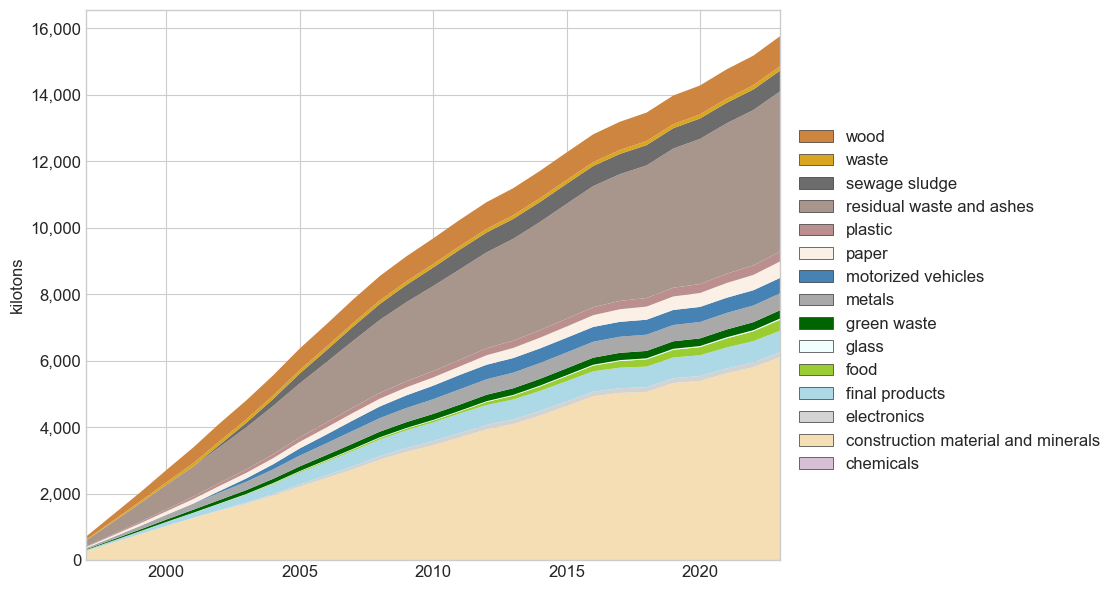

In [100]:
id="plot"

plt.rcParams.update({
    "axes.labelsize": 12,   # Achsenbeschriftung
    "xtick.labelsize": 12,  # x-Ticks
    "ytick.labelsize": 12   # y-Ticks
})


fig, ax = plt.subplots(figsize=(8, 6))

plt.xlim(1997, 2023) 

ax.stackplot(
    area_df_cum.index,
    area_df_cum.T.values,
    edgecolor="none",
    labels=materials,
    colors=colors
)


legend_handles = [
    Patch(facecolor=c, edgecolor="#333333", label=m, linewidth=0.5)
    for m, c in reversed(list(zip(materials, colors)))
]


fig.legend(
    handles=legend_handles,
    loc="upper right",
    bbox_to_anchor=(1.4, 0.8),
    ncol=1,
    frameon=False,
    #title="Material",
    fontsize=12,
    title_fontsize=12
)
#ax.set_xlabel("Year")
ax.set_ylabel("kilotons")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ",")))
#ax.set_title("Accumulated waste in O'ahu's landfills from 1997 - 2023", fontsize = 14, fontweight="bold")

plt.tight_layout()
fig.savefig('landfill_accumulation_revised.jpg', dpi = 600,bbox_inches='tight')
plt.show()

__Exports__

In [103]:
### displaying the revised exports version
exp = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/Imports_Exports/total_exp.xlsx")

In [105]:
display(exp)

,Material,Source,Target,Year,Commodity Description,kilotons
0,chemicals,DMI,Exports,1997,Basic chemicals,1.959304
1,chemicals,DMI,Exports,1997,Chemical prods.,3.077776
2,chemicals,DMI,Exports,1997,Fertilizers,1.939737
3,chemicals,DMI,Exports,1997,Pharmaceuticals,0.905373
4,chemicals,DMI,Exports,2002,Basic chemicals,1.233983
...,...,...,...,...,...,...
242,wood,DMI,Exports,2012,Wood prods.,26.226782
243,wood,DMI,Exports,2017,Logs and Other Wood in the Rough,0.114600
244,wood,DMI,Exports,2017,Wood Products,6.146500
245,wood,DMI,Exports,2022,Logs,0.049180


In [107]:
F1_0 = exp

In [109]:
F1_0.head()

,Material,Source,Target,Year,Commodity Description,kilotons
0,chemicals,DMI,Exports,1997,Basic chemicals,1.959304
1,chemicals,DMI,Exports,1997,Chemical prods.,3.077776
2,chemicals,DMI,Exports,1997,Fertilizers,1.939737
3,chemicals,DMI,Exports,1997,Pharmaceuticals,0.905373
4,chemicals,DMI,Exports,2002,Basic chemicals,1.233983


In [111]:
F1_0 = F1_0[["Material", "Source", "Target", "kilotons", "Year"]]

In [113]:
F1_0 = (
    F1_0
    .groupby(["Year", "Material"], as_index=False)["kilotons"]
    .sum()
)

In [115]:
display(F1_0)

,Year,Material,kilotons
0,1997,chemicals,7.882189
1,1997,construction material and minerals,110.874018
2,1997,electronics,18.302696
3,1997,final products,60.080318
4,1997,food,287.114119
...,...,...,...
73,2022,motorized vehicles,21.879353
74,2022,paper,17.157192
75,2022,plastic,15.218026
76,2022,waste,43.187501


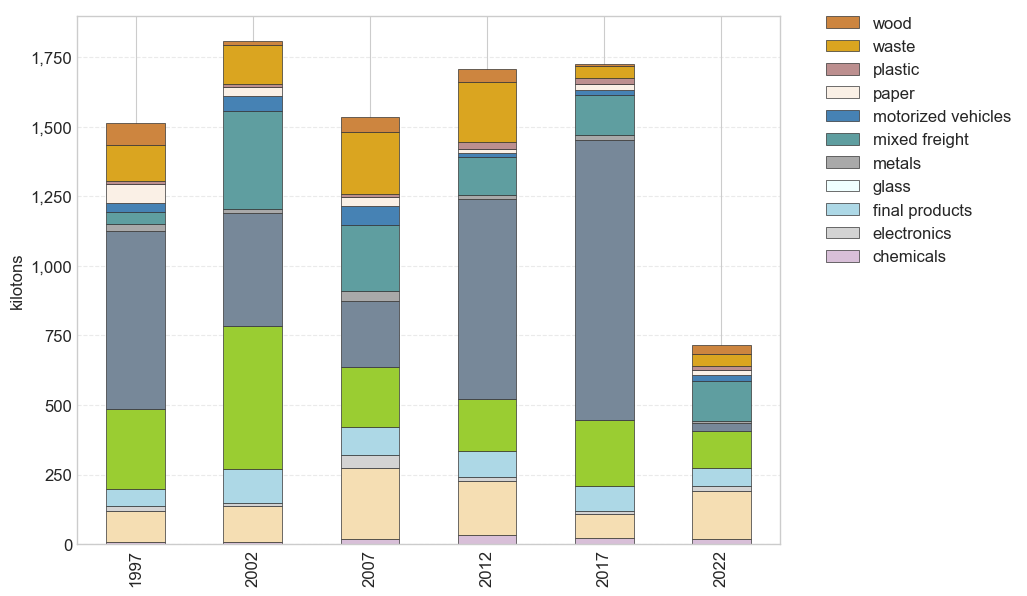

In [117]:
plt.style.use("seaborn-v0_8-whitegrid")

pivot_df = F1_0.pivot(
    index="Year",
    columns="Material",
    values="kilotons"
)

fig, ax = plt.subplots(figsize=(8, 6))

pivot_df.plot.bar(
    stacked=True,
    color=[product_colors[col] for col in pivot_df.columns],
    edgecolor = "#333333",
    linewidth = 0.5,
    ax=ax,
    legend=False
)

ax.set_facecolor("white")
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
#ax.set_axisbelow(True)

# Titel
#ax.set_title("Exports", fontsize=12, fontweight="bold")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
)

legend_handles = [
    Patch(
        facecolor=product_colors.get(mat, "#cccccc"),
        edgecolor="#333333",
        linewidth=0.5,
        label=mat
    )
    for mat in reversed(materials2)
]

fig.legend(
    handles=legend_handles,
    title="",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize = 12
)
fig.subplots_adjust(right=0.75)

ax.set_ylabel("kilotons")
ax.set_xlabel("")

plt.tight_layout()
fig.savefig('Exports.jpg', dpi = 600,bbox_inches='tight')
plt.show()

## Sankey diagrams

To create sankey diagrams, we need to create one big dataframe, always containing source and target columns, combining in- and outflows of processes.

In [120]:
#read the data
F0a_1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F0a_1")
F0b_1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F0b_1")
F1_3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F1_3")
F2_1 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F2_1")
F1_0 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "total_exp") 
F3_0 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F3_0")
F3_4 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F3_4")
F5_3 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "reuse_flows") #precalculated data, based on F9_0 and C&D reuse
F5_7 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_7")
F5_6 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_6")
F5_8 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_8")
F5_9 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F5_9")
F7_8 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F7_8")
F7_9 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F7_9")
deltaS8 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "deltaS8")
F9_0 = pd.read_excel("C:/Users/linsmasa/ODYM-master/revised_model/SI2_revised.xlsx", "F9_0") #with m != "green waste","food" and "final products"

F0a_1 = F0a_1[F0a_1['Year'].isin(years)]
F0b_1 = F0b_1[F0b_1['Year'].isin(years)]
F1_3 = F1_3[F1_3['Year'].isin(years)]
F2_1 = F2_1[F2_1['Year'].isin(years)]
F1_0 = F1_0[F1_0['Year'].isin(years)]
F3_4 = F3_4[F3_4['Year'].isin(years)]
F5_3 = F5_3[F5_3['Year'].isin(years)]
F5_7 = F5_7[F5_7['Year'].isin(years)]
F5_6 = F5_6[F5_6['Year'].isin(years)]
F5_8 = F5_8[F5_8['Year'].isin(years)]
F5_9 = F5_9[F5_9['Year'].isin(years)]
F7_8 = F7_8[F7_8['Year'].isin(years)]
F7_9 = F7_9[F7_9['Year'].isin(years)]
F9_0 = F9_0[F9_0['Year'].isin(years)]

F3_4 = F3_4[F3_4['Material'] != "sewage sludge (tonnage data being researched)"]

exclude = ['green waste', 'food', 'final products', 'sewage sludge (tonnage data being researched)']
F9_0 = F9_0[~F9_0["Material"].isin(exclude)]
F9_0 = (F9_0.rename(columns={'Tons':'kilotons'})
       .groupby(['Material', 'Year'], as_index=False)['kilotons']
       .sum())

In [140]:
df = pd.concat([F0a_1,F0b_1,F1_3,F2_1,F1_0,F3_0,F3_4,F4_5,F5_3,F5_7,F5_6,F5_8,F5_9,F7_8,F7_9], ignore_index=True) #F9_0 is excluded

In [142]:
df.head()

,Year,Material,Source,Target,kilotons,Commodity Description
0,1997,chemicals,Imports,DMI,69.728243,NaN
1,1997,construction material and minerals,Imports,DMI,587.528504,NaN
2,1997,electronics,Imports,DMI,32.311510,NaN
3,1997,final products,Imports,DMI,198.335201,NaN
4,1997,food,Imports,DMI,692.187348,NaN


In [144]:
source = set(df['Source'])
target = set(df['Target']) # check if all names match

In [146]:
df = df[df['Material'] != 'sewage sludge (tonnage data being researched)']

In [148]:
df= df.groupby(['Year','Source', 'Target', 'Material']).agg({f'kilotons': 'sum'}).reset_index()
df.head()

,Year,Source,Target,Material,kilotons
0,1997,DE,DMI,construction material and minerals,4443.415673
1,1997,DE,DMI,food,367.762911
2,1997,DMC,DFC,food,493.910000
3,1997,DMC,NAS,chemicals,61.846054
4,1997,DMC,NAS,construction material and minerals,5124.470159


In [150]:
#add Reuse and Recycling on island as a dummy flow to show circularity
rr = df[df['Source'] == 'EoL']
rr = rr[rr['Target'] == 'NAS']
rr['Source'] = 'Reuse and Recycling'
rr['Target'] = 'NAS'
mask = (df["Source"] == "EoL") & (df["Target"] == "NAS")
df.loc[mask, "Target"] = "Reuse and Recycling"
df = pd.concat([df, rr], ignore_index = True)

In [152]:
#add Reuse and Recycling on island as a dummy flow to show circularity
rr = df[df['Source'] == 'EoL']
rr = rr[rr['Target'] == 'NAS']
rr['Source'] = 'Reuse and Recycling'
rr['Target'] = 'NAS'

rec = rr.copy()
rec['Source'] = 'EoL'
rec['Target'] = 'Reuse and Recycling'

#remove this from df:
mask = (df["Source"] == "EoL") & (df["Target"] == "NAS")
df = df[~mask]

df = pd.concat([df, rec, rr], ignore_index = True)

In [154]:
# Convert source and target labels to unique numeric indices
nodes = list(set(df['Source']).union(set(df['Target'])))
node_indices = {node: idx for idx, node in enumerate(nodes)}
source_indices = [node_indices[source] for source in df['Source']]
target_indices = [node_indices[target] for target in df['Target']]

In [156]:
nodes

['Imports',
 'landfills',
 'Indirect Imports of Packaging',
 'DMI',
 'NAS',
 'Recycling off island',
 'DE',
 'DMC',
 'Composting',
 'WtE',
 'Exports',
 'DFC',
 'EoL']

In [158]:
df.to_excel("sankey_data.xlsx", index = False)

#### 2022 Sankey, for one specific material

In [160]:
node_indices ={
    "DE": 0, 
    "Imports": 1, 
    "Indirect Imports of Packaging": 2, 
    "DMI": 3, 
    "DMC": 4,
    "DFC": 4,
    "NAS": 5, 
    "Reuse and Recycling": 6, 
    "EoL": 7, 
    "Composting": 8,
    "Exports": 9, 
    "WtE": 10, 
    "Recycling off island": 11, 
    "landfills": 12
}

nodes = [None] * len(node_indices)
for name, idx in node_indices.items():
    nodes[idx] = name
    
source_indices = [node_indices[source] for source in data['Source']]
target_indices = [node_indices[target] for target in data['Target']]
#source_indices, target_indices

C:\Users\linsmasa\anaconda3\Lib\site-packages\kaleido\_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




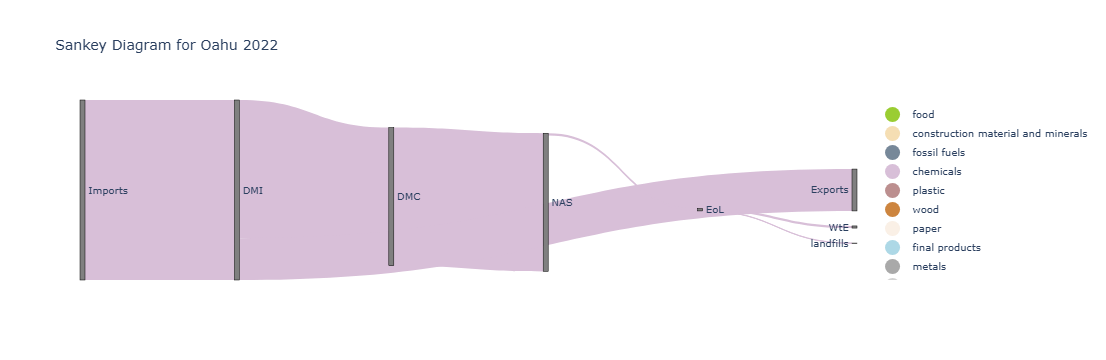

In [162]:
# Create the Sankey diagram for any material and year
year = 2022
material = 'chemicals'

data = df.copy()

data = data[data['Year'] == year]
data = data[data['Material'] == material]

# Convert source and target labels to unique numeric indices
nodes = list(set(data['Source']).union(set(data['Target'])))
node_indices = {node: idx for idx, node in enumerate(nodes)}
source_indices = [node_indices[source] for source in data['Source']]
target_indices = [node_indices[target] for target in data['Target']]

fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=5,
        line=dict(color="black", width=0.5),
        label=nodes,  # Unique labels for nodes
        color="grey"
    ),
    link=dict(
        source=source_indices,  # Source node indices
        target=target_indices,  # Target node indices
        value=data['kilotons'],     # Flow values
        color=[product_colors[product] for product in data['Material']]  # Link colors based on product
    )
)])
    
# Customize layout
fig.update_layout(
    title_text=f"Sankey Diagram for Oahu {year}", font_size=10,
    xaxis_title=None,  # Entfernt die Beschriftung der x-Achse
    yaxis_title=None,  # Entfernt die Beschriftung der y-Achse)
    xaxis=dict(showticklabels=False),  # Entfernt die Tick-Labels der x-Achse
    yaxis=dict(showticklabels=False),   # Entfernt die Tick-Labels der y-Achse
    plot_bgcolor="rgba(0,0,0,0)",  # Entfernt den Plot-Hintergrund (transparent)
    paper_bgcolor="rgba(0,0,0,0)")  # Entfernt den gesamten Figurenhintergrund (transparent)
    
# Add custom legend as scatter traces
for sctg2, color in product_colors.items():
    fig.add_trace(go.Scatter(
        x=[None],  # Dummy x value
        y=[None],  # Dummy y value
        mode='markers',
        marker=dict(size=15, color=color),
        name=sctg2,  # Legend entry
        hoverinfo='none'  # Hide hover text for dummy points
    ))
    
# Show the Sankey diagram
fig.show()

### 2022 Sankey, all materials except: fossil fuels, food, construction material and minerals, sewage sludge, waste, green waste

     Year Source Target                            Material     kilotons
697  2022     DE    DMI  construction material and minerals  4387.293043
698  2022     DE    DMI                                food   489.847440


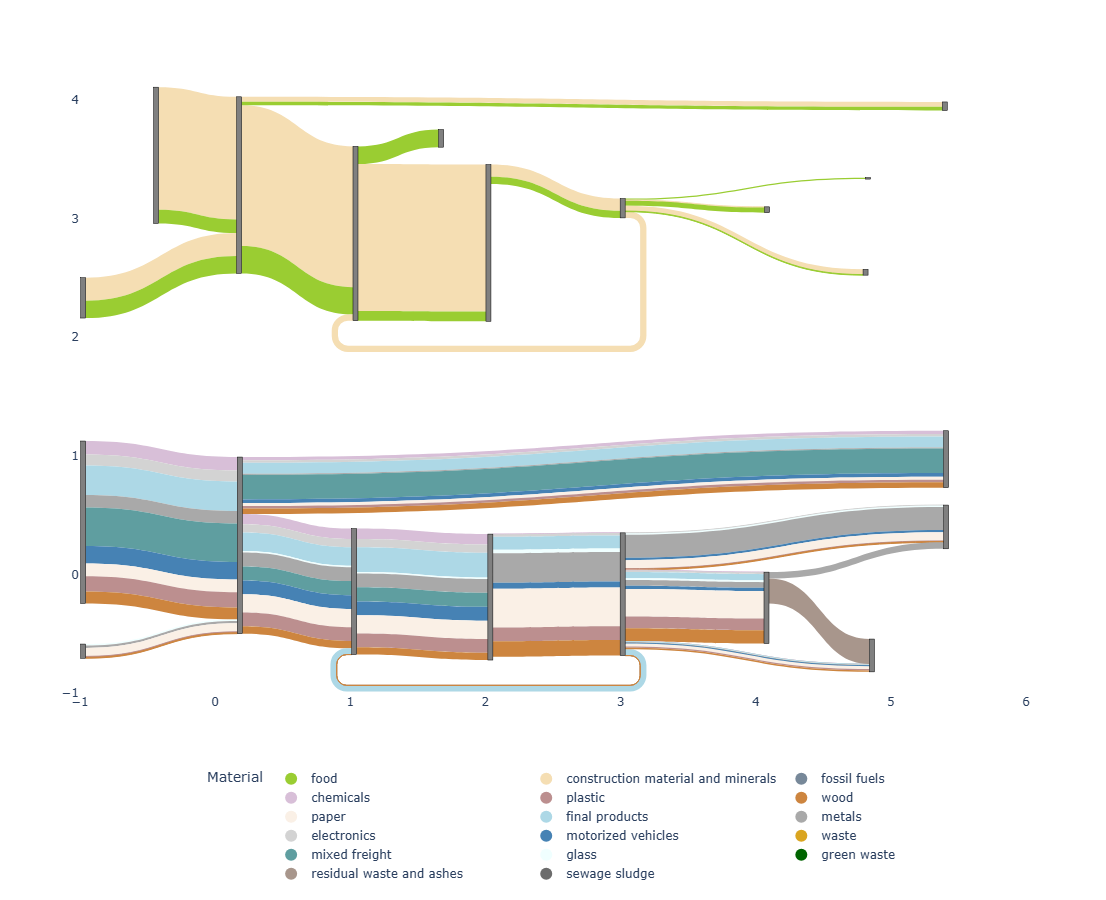

In [171]:
# dual sankey diagram, 2 rows, 1 column
fig = make_subplots(
    rows=2,
    cols=1,
    specs=[[{"type": "domain"}], 
            [{"type": "domain"}]],
    horizontal_spacing=0.08
)

# sankey 1 - high-volume materials
data1 = df.copy()

include = [ 'food', 
           'construction material and minerals']

data1 = data1[(data1['Year'] == 2022) &
              (data1['Material'].isin(include))]

node_indices ={
    "DE": 0, 
    "Imports": 1, 
    "Indirect Imports of Packaging": 2, 
    "DMI": 3, 
    "DMC": 4,
    "DFC": 5,
    "NAS": 6, 
    "Reuse and Recycling": 7, 
    "EoL": 8, 
    "Composting": 9,
    "Exports": 10, 
    "WtE": 11, 
    "Recycling off island": 12, 
    "landfills": 13
}

nodes = [None] * len(node_indices)
for name, idx in node_indices.items():
    nodes[idx] = name
    
source_indices = [node_indices[source] for source in data1['Source']]
target_indices = [node_indices[target] for target in data1['Target']]
source_indices, target_indices

fig.add_trace(
    go.Sankey(
        arrangement="freeform",
        node=dict(
            pad=15,
            thickness=5,
            line=dict(color="black", width=0.5),
            label=nodes,
            color="grey"
        ),
        link=dict(
            source=[node_indices[s] for s in data1['Source']],
            target=[node_indices[t] for t in data1['Target']],
            value=data1['kilotons'],
            color=[product_colors[p] for p in data1['Material']]
        )#,
        #showlegend=False
    ),
    row=1, col=1
)

print(data1[(data1['Source'] == 'DE') | (data1['Target'] == 'DE')])

# sankey 2 - low-volume materials
data2 = df.copy()
exclude = ['green waste', 'food', 'fossil fuels',
           'sewage sludge', 'waste',
           'construction material and minerals']

data2 = data2[(data2['Year'] == 2022) &
              (~data2['Material'].isin(exclude))]

# nodes = [n for n in ordered_nodes 
#           if n in set(data2['Source']).union(set(data2['Target']))]

# node_indices = {node: idx for idx, node in enumerate(nodes)}
node_indices ={
    "DE": 0, 
    "Imports": 1, 
    "Indirect Imports of Packaging": 2, 
    "DMI": 3, 
    "DMC": 4,
    "DFC": 4,
    "NAS": 5, 
    "Reuse and Recycling": 6, 
    "EoL": 7, 
    "Composting": 8,
    "Exports": 9, 
    "WtE": 10, 
    "Recycling off island": 11, 
    "landfills": 12
}


nodes = [None] * len(node_indices)
for name, idx in node_indices.items():
    nodes[idx] = name
    
source_indices = [node_indices[source] for source in data2['Source']]
target_indices = [node_indices[target] for target in data2['Target']]
source_indices, target_indices

# nodes = list(set(data2['Source']).union(set(data2['Target'])))
# node_indices = {node: idx for idx, node in enumerate(nodes)}

fig.add_trace(
    go.Sankey(
        arrangement="freeform",
        node=dict(
            pad=15,
            thickness=5,
            line=dict(color="black", width=0.5),
            label=nodes,
            color="grey"
        ),
        link=dict(
            source=[node_indices[s] for s in data2['Source']],
            target=[node_indices[t] for t in data2['Target']],
            value=data2['kilotons'],
            color=[product_colors[p] for p in data2['Material']]
        )#,
        #showlegend=False
    ),
    row=2, col=1
)

# same legend
for material, color in product_colors.items():
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            marker=dict(size=12, color=color),
            name=material,
            hoverinfo="none",
            showlegend=True
        )#,
        #row=2, col=1
    )

fig.update_traces(
    selector=dict(type="sankey"),
    textfont=dict(
        color="rgba(0,0,0,0)"
    )
)

# layout
fig.update_layout(
    height=900,
    width = 900,
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.12,
        xanchor="center",
        x=0.5,
        title="Material",
        traceorder="normal"
    ),
    margin=dict(b=140),
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="rgba(0,0,0,0)"
)

fig.show()

In [257]:
# fig.write_html("sankeys.html")
# fig.write_image("NAS_comparison.jpg", scale=6)

ValueError: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


### Heatmaps

In [103]:
sns.set_theme(style="white")
plt.rcParams["figure.dpi"] = 150

In [105]:
df["share"] = (
    df["kilotons"] /
    df.groupby(["Material", "Year"])["kilotons"].transform("sum")
)

In [107]:
materials = sorted(df["Material"].unique())

In [109]:
# sns.set_theme(style="white")

plt.rcParams.update({
    "figure.dpi":150,
    "font.size":11,
    "axes.titlesize":12,
    "axes.labelsize":11
})

In [111]:
strategies = [
    "reuse, recycling and composting",
    "exports for recycling",
    "WtE",
    "landfills"
]
comp_reuse["strategy"] = "reuse, recycling and composting"
F9_0["strategy"] = "exports for recycling"
F5_7["strategy"] = "WtE"
deltaS8["strategy"] = "landfills"

In [113]:
df = pd.concat([comp_reuse, F9_0, F5_7, deltaS8], ignore_index=True)

In [115]:
df["share"] = (
    df["kilotons"] /
    df.groupby(["Material", "Year"])["kilotons"].transform("sum")
)

materials = sorted(df["Material"].unique())
years = sorted(df["Year"].unique())

In [117]:
base_cmap = sns.color_palette("flare", as_cmap=True)
#https://seaborn.pydata.org/tutorial/color_palettes.html

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\3643138081.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\3643138081.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\3643138081.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\3643138081.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\3643138081.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\3643138081.py:30:

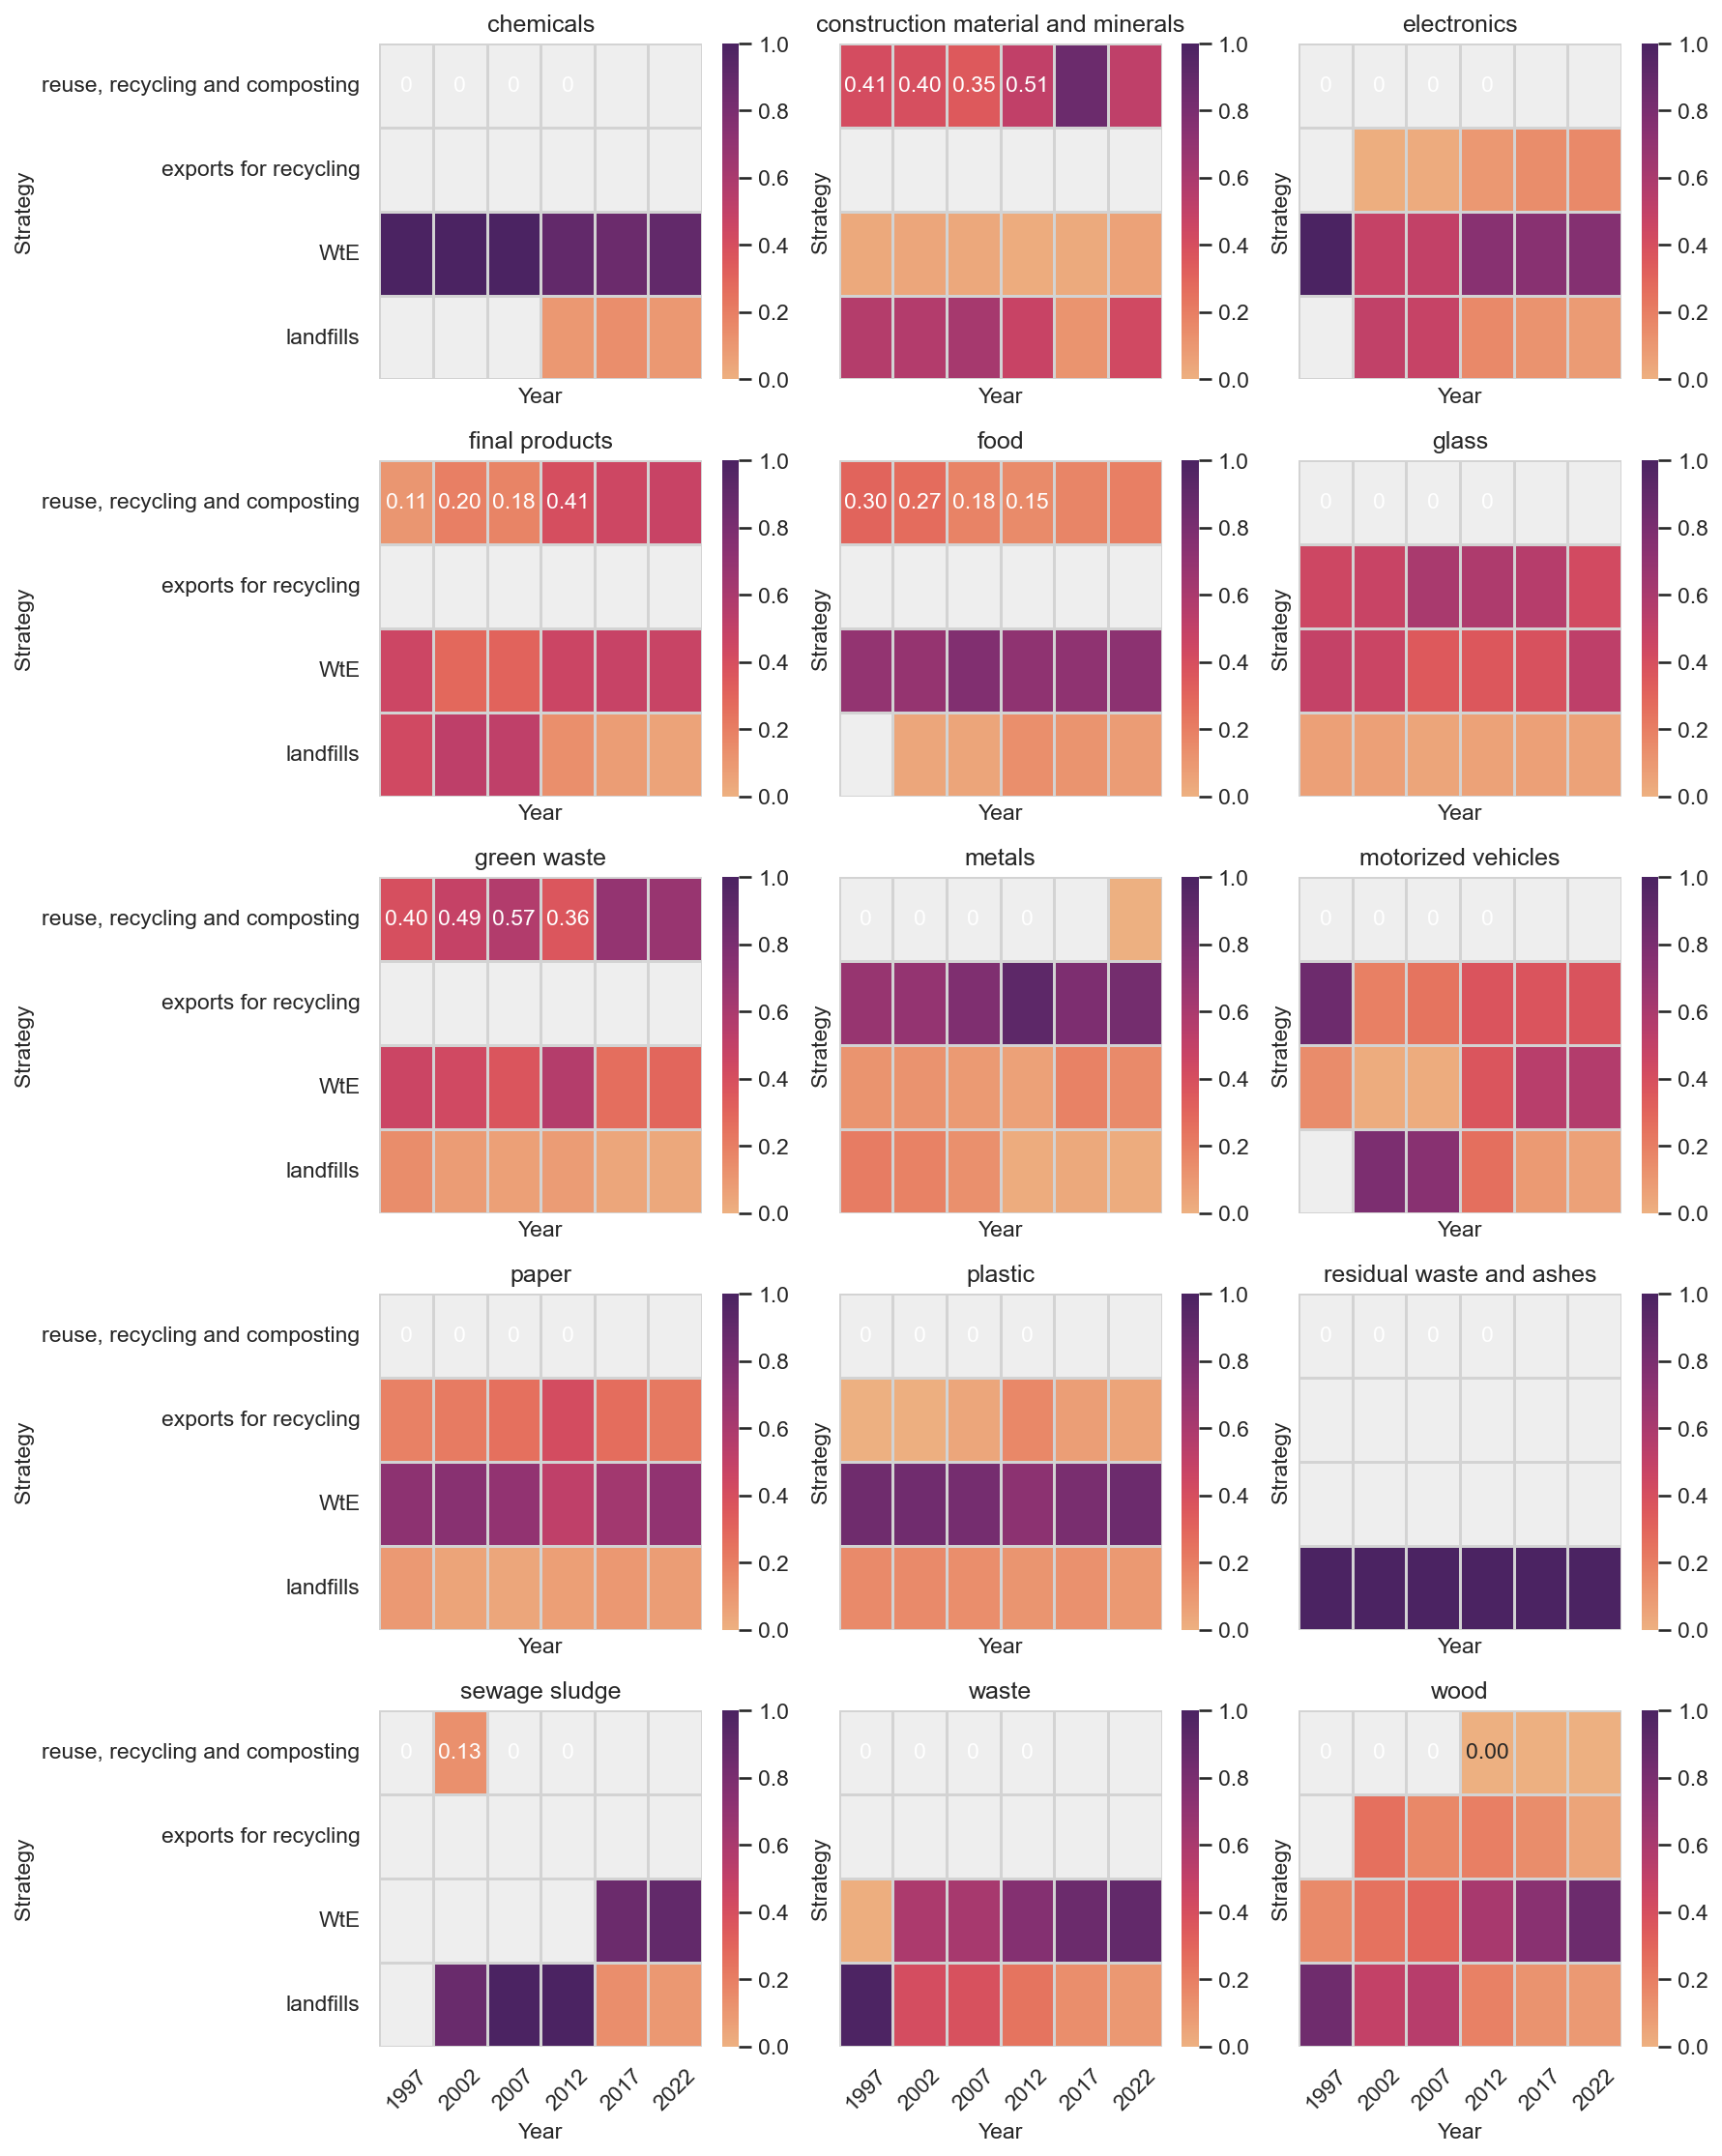

In [119]:
# Figure containing all heatmaps
n_cols = min(3, len(materials))
n_rows = int(np.ceil(len(materials)/n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4*n_cols, 3*n_rows),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, material in zip(axes, materials):

    data_material = df[df["Material"] == material]

    heatmap_data = data_material.pivot_table(
        index="strategy",
        columns="Year",
        values="share"
    )

    heatmap_data = heatmap_data.reindex(
        index=strategies,
        columns=years
    ).fillna(0)

    annot = heatmap_data.applymap(
        lambda x: "0" if x == 0 else f"{x:.2f}"
    )

    mask = heatmap_data == 0

    # Haupt-Heatmap
    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap="flare",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="lightgrey",
        annot=annot,
        fmt="",
        mask=mask,
        cbar=True
    )

    # graue Felder für echte Nullen
    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap=ListedColormap(["#eeeeee"]),
        mask=~mask,
        cbar=False,
        linewidths=0.5,
        linecolor="lightgrey"
    )

    ax.set_title(material)
    ax.set_xticklabels(years, rotation = 45)
    ax.set_xlabel("Year")
    ax.set_ylabel("Strategy")
    

# leere Achsen entfernen
for i in range(len(materials), len(axes)):
    fig.delaxes(axes[i])
plt.savefig('waste_management_strategies.jpg', dpi = 600,bbox_inches='tight')
plt.tight_layout()
plt.show()

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\2249711520.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\2249711520.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\2249711520.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\2249711520.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\2249711520.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = heatmap_data.applymap(
C:\Users\linsmasa\AppData\Local\Temp\ipykernel_18628\2249711520.py:46:

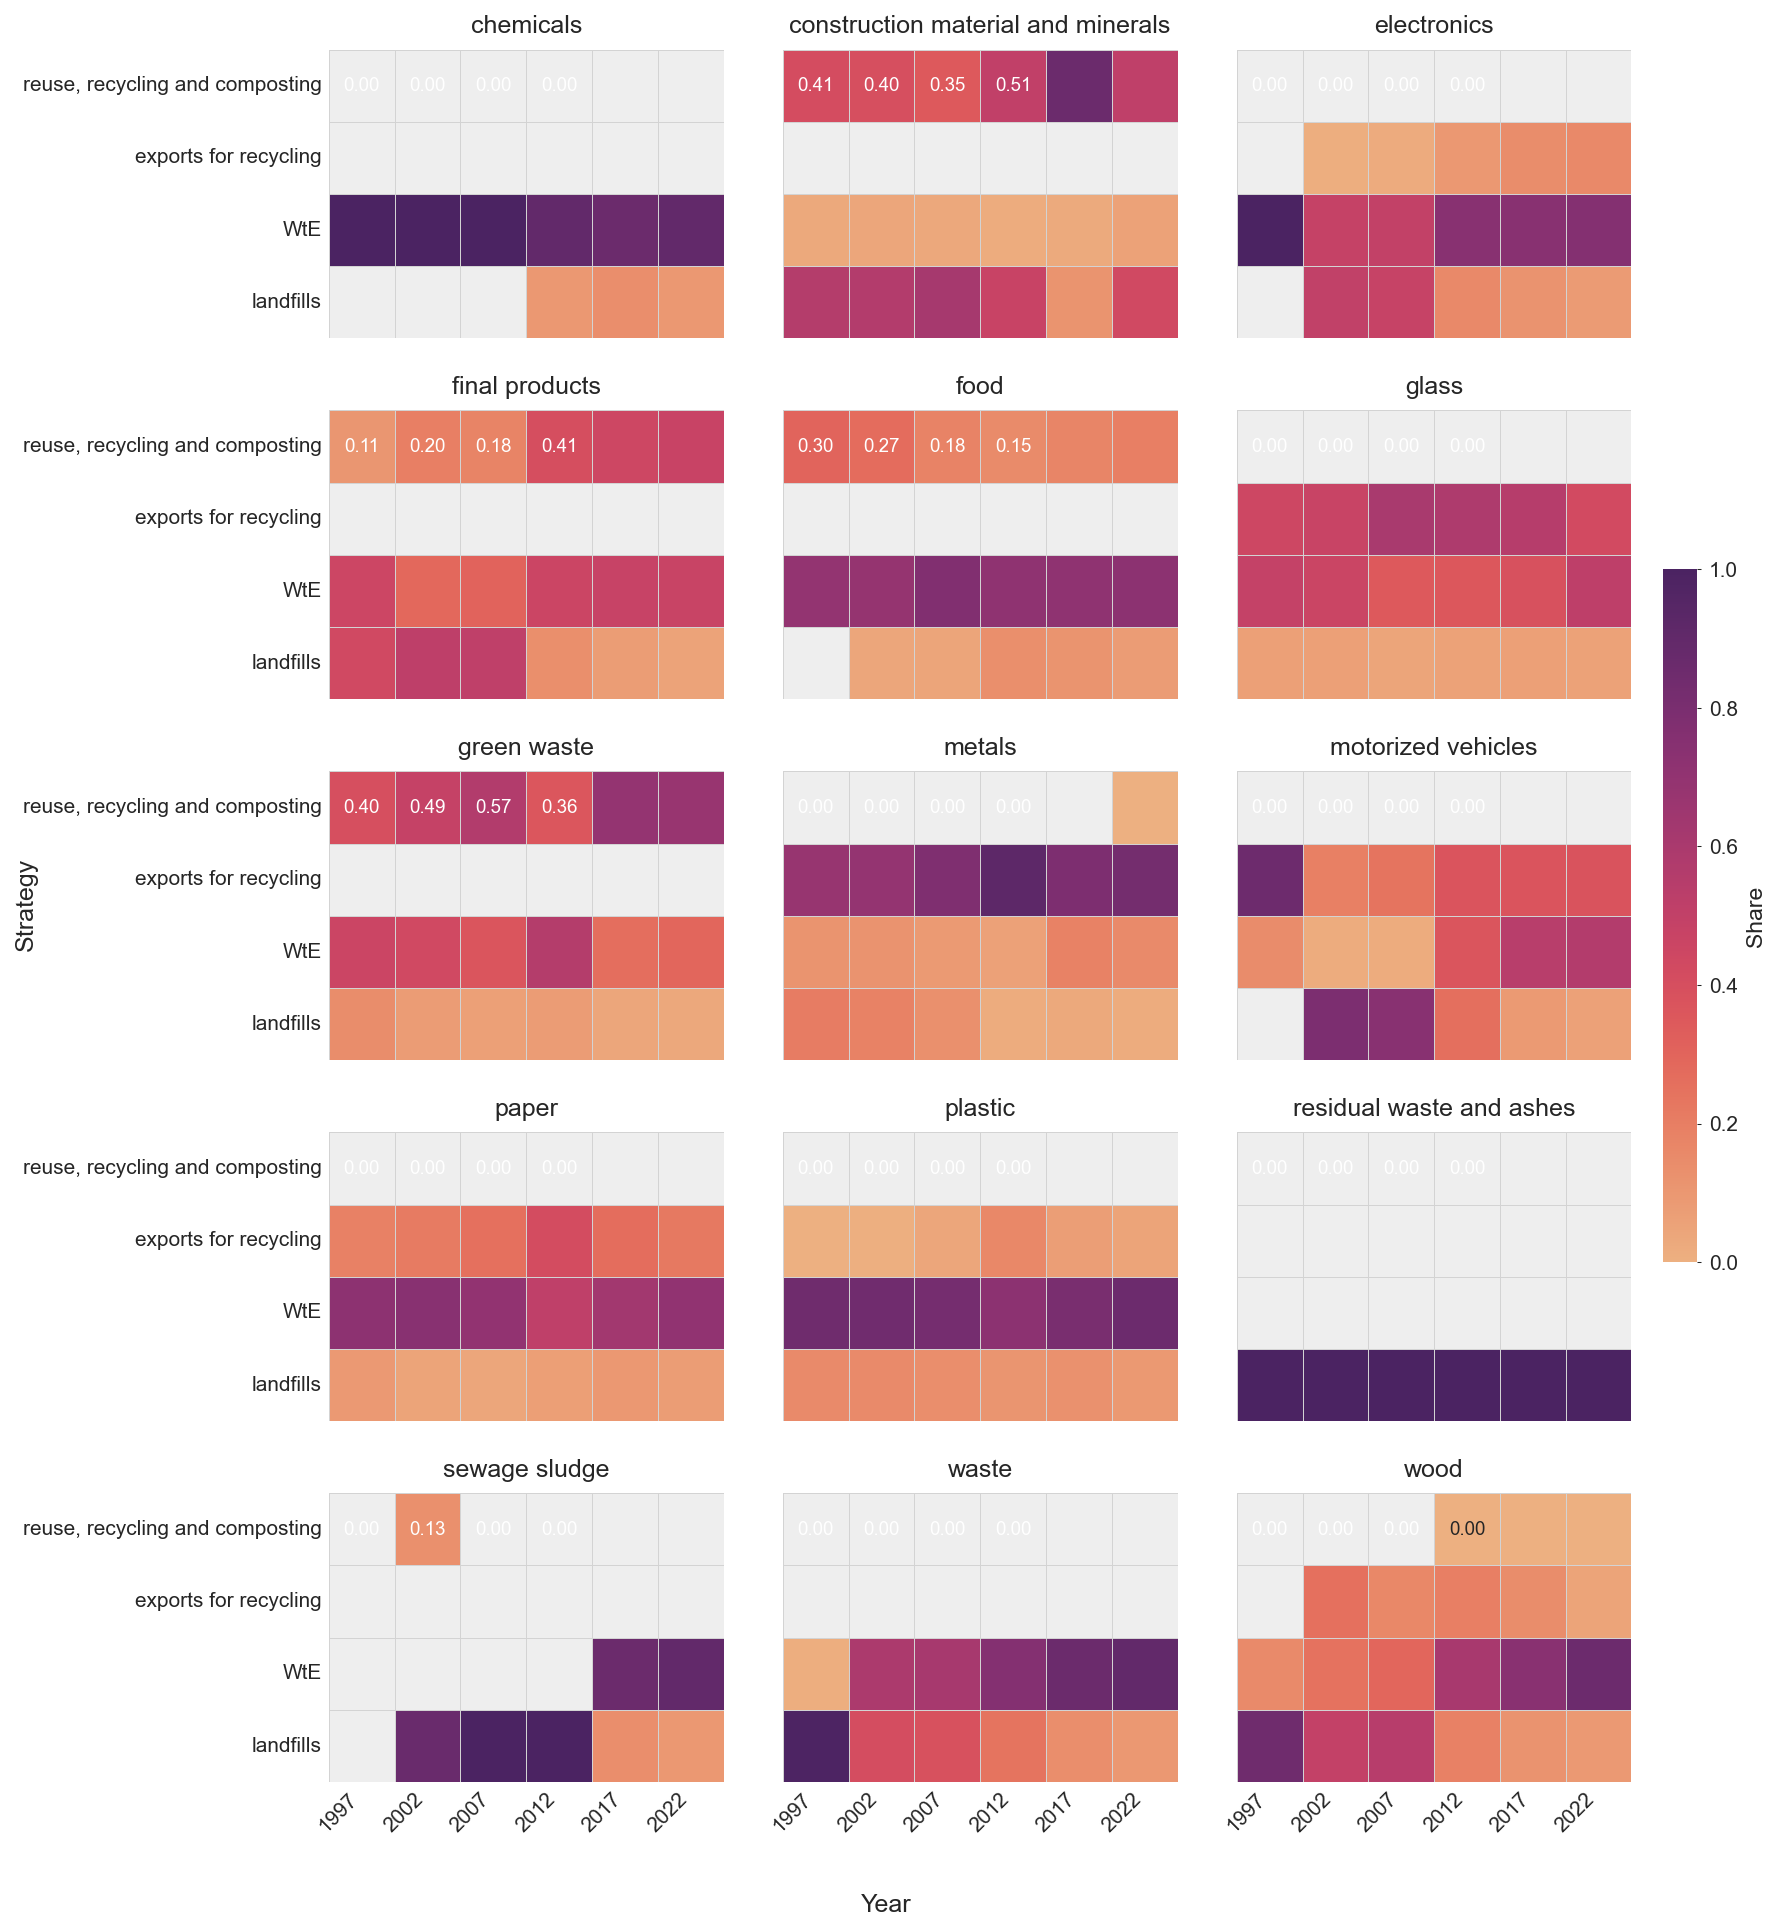

In [147]:
#revised version

# import numpy as np
# import seaborn as sns
# import matplotlib.pyplot as plt
# import matplotlib as mpl
# from matplotlib.colors import ListedColormap

# Figure layout
n_cols = min(3, len(materials))
n_rows = int(np.ceil(len(materials) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4.5 * n_cols, 3.0 * n_rows),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    wspace=0.15,
    hspace=0.25
)
axes = np.array(axes).flatten()

# common color scale
norm = mpl.colors.Normalize(vmin=0, vmax=1)
cmap = sns.color_palette("flare", as_cmap=True)

for i, (ax, material) in enumerate(zip(axes, materials)):

    data_material = df[df["Material"] == material]

    heatmap_data = data_material.pivot_table(
        index="strategy",
        columns="Year",
        values="share"
    )

    heatmap_data = heatmap_data.reindex(
        index=strategies,
        columns=years
    ).fillna(0)

    annot = heatmap_data.applymap(
        lambda x: f"{x:.2f}"
    )

    mask = heatmap_data == 0

    # main heatmap
    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap=cmap,
        vmin=0,
        vmax=1,
        linewidths=0.4,
        linecolor="lightgrey",
        annot=annot,
        fmt="",
        mask=mask,
        cbar=False,
        annot_kws={"size": 9}
    )

    # grey for zeros
    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap=ListedColormap(["#eeeeee"]),
        mask=~mask,
        cbar=False,
        linewidths=0.4,
        linecolor="lightgrey"
    )

    # title
    ax.set_title(material, fontsize=12, pad=8)

    # # frame around heatmaps (does not work)
    # for spine in ax.spines.values():
    #     spine.set_visible(True)
    #     spine.set_edgecolor("#cccccc")
    #     spine.set_linewidth(0.8)

    # axes labels
    ax.set_xlabel("")
    ax.set_ylabel("")

    # x-axis
    if i // n_cols == n_rows - 1:
        ax.set_xticklabels(
            years,
            rotation=45,
            ha="right",
            fontsize=10
        )
    else:
        ax.tick_params(axis="x", labelbottom=False)

    # y-axis
    if i % n_cols == 0:
        ax.set_yticklabels(
            ax.get_yticklabels(),
            rotation=0,
            fontsize=10
        )
    else:
        ax.tick_params(axis="y", labelleft=False)

    ax.tick_params(length=0)

    # # light grey background
    # ax.set_facecolor("#fafafa")
    
    # for spine in ax.spines.values():
    #     spine.set_visible(True)
    #     spine.set_edgecolor("#d0d0d0")
    #     spine.set_linewidth(0.8)

# remove empty axes
for i in range(len(materials), len(axes)):
    fig.delaxes(axes[i])

# shared axes
fig.supxlabel("Year", 
              fontsize=12,
              x = 0.4,
              y = 0.05)
fig.supylabel("Strategy", 
              fontsize=12,
              x = -0.03,
              y = 0.5)

# one colorbar
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# fig.colorbar(
#     sm,
#     ax=axes[:len(materials)].tolist(),
#     label="Share",
#     shrink=0.5,
#     pad=0.02
# )
cbar = fig.colorbar(
    sm,
    ax=axes[:len(materials)].tolist(),
    shrink=0.4,
    pad=0.02
)

cbar.outline.set_visible(False)
cbar.set_label("Share", fontsize=11)
cbar.ax.tick_params(labelsize=10, length=2, width=0.5)

# Export
plt.savefig(
    "waste_management_strategies.jpg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


In [173]:
# # output folder for single heatmaps
# output_folder = "heatmaps_materials"
# os.makedirs(output_folder, exist_ok=True)


# for material in materials:

#     data_material = df[df["Material"] == material]

#     heatmap_data = data_material.pivot_table(
#         index="strategy",
#         columns="Year",
#         values="share"
#     )

#     heatmap_data = heatmap_data.reindex(
#         index=strategies,
#         columns=years
#     ).fillna(0)

#     annot = heatmap_data.applymap(
#         lambda x: "0" if x == 0 else f"{x:.2f}"
#     )

#     mask = heatmap_data == 0

#     fig, ax = plt.subplots(
#         figsize=(6, 4)
#     )

#     sns.heatmap(
#         heatmap_data,
#         ax=ax,
#         cmap="flare",
#         vmin=0,
#         vmax=1,   # same scale for all heat maps
#         linewidths=0.5,
#         linecolor="lightgrey",
#         annot=annot,
#         fmt="",
#         mask=mask,
#         cbar=True,
#         cbar_kws={
#             "label": "Share"
#         }
#     )

#     sns.heatmap(
#         heatmap_data,
#         ax=ax,
#         cmap=ListedColormap(["#eeeeee"]),
#         mask=~mask,
#         cbar=False,
#         linewidths=0.5,
#         linecolor="lightgrey"
#     )

#     ax.set_title(material, fontsize=14)

#     ax.set_xlabel("Year")
#     #ax.set_ylabel("Strategy")

#     ax.set_xticklabels(
#         years,
#         rotation=45,
#         ha="right"
#     )


#     # save images
#     # filename = f"{output_folder}/heatmap_{material}.jpg"

#     # plt.savefig(
#     #     filename,
#     #     dpi=600,
#     #     bbox_inches="tight"
#     # )

#     # plt.close()


# #print("All heatmaps are saved.")